In [1]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

groq_api_key=os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq
llm=ChatGroq(groq_api_key=groq_api_key,model="openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x705e3bc72660>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x705e3bc730e0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [3]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

In [ ]:
from langchain_tavily import TavilySearch

tavily_tool=TavilySearch(max_results=2) 

In [5]:
## Custom function
def multiply_tool(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [6]:
tools=[tavily_tool,multiply_tool]
llm_with_tools=llm.bind_tools(tools)
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x705e3bc72660>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x705e3bc730e0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted

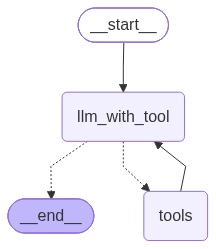

In [7]:
from langgraph.prebuilt import ToolNode,tools_condition

def llm_with_tool(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

graph_builder=StateGraph(State)
graph_builder.add_node("llm_with_tool",llm_with_tool)
graph_builder.add_node("tools",ToolNode(tools))

graph_builder.add_edge(START,"llm_with_tool")
graph_builder.add_conditional_edges(
    "llm_with_tool",
    tools_condition
)
graph_builder.add_edge("tools","llm_with_tool",)

## compile the graph
graph=graph_builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [8]:
response=graph.invoke({"messages":"My name is Anas"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

My name is Anas
================================== Ai Message ==================================

Nice to meet you, Anas! How can I help you today?


In [9]:
response=graph.invoke({"messages":"What is my Name?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my Name?
================================== Ai Message ==================================

I don’t have that information—could you let me know your name?


### Adding Memory

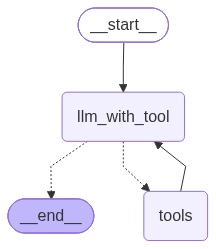

In [10]:
from langgraph.checkpoint.memory import MemorySaver
# Saves Mem using defaulkt Dict

memory=MemorySaver()

from langgraph.prebuilt import ToolNode,tools_condition

def llm_with_tool(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

graph_builder=StateGraph(State)
graph_builder.add_node("llm_with_tool",llm_with_tool)
graph_builder.add_node("tools",ToolNode(tools))

graph_builder.add_edge(START,"llm_with_tool")
graph_builder.add_conditional_edges(
    "llm_with_tool",
    tools_condition
)
graph_builder.add_edge("tools","llm_with_tool")

## compile the graph
graph=graph_builder.compile(checkpointer=memory)  #### Added Memory

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
config={"configurable":{"thread_id":"1"}}


response=graph.invoke({"messages":"My name is Anas"},config=config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

My name is Anas
================================== Ai Message ==================================

Nice to meet you, Anas! How can I assist you today?


In [12]:
response=graph.invoke({"messages":"What is my name?"},config=config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

My name is Anas
================================== Ai Message ==================================

Nice to meet you, Anas! How can I assist you today?
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Your name is Anas.


In [13]:
response

{'messages': [HumanMessage(content='My name is Anas', additional_kwargs={}, response_metadata={}, id='cc1b0393-ab46-45ad-9bac-663f33edad0d'),
  AIMessage(content='Nice to meet you, Anas! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "My name is Anas". Likely just greeting. We can respond politely, ask how to help. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 348, 'total_tokens': 402, 'completion_time': 0.066207405, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.023881306, 'prompt_tokens_details': None, 'queue_time': 0.064794324, 'total_time': 0.090088711}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e99e93f2ac', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1efa9-afae-7611-bbab-d5638a7180eb-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens': 54,

In [14]:
response["messages"][-1].content

'Your name is Anas.'